# Weighting potential e weighting field di un detector ICPC (LEGEND)

Calcolo e visualizzazione del **potenziale pesante** ($\Phi_w$) e del **campo pesante**
($\vec{E}_w = -\nabla\Phi_w$) per un detector HPGe di tipo ICPC, a partire dal file di
metadata JSON in formato `legend-metadata`.

**Metodo.** Il weighting potential non dipende dal bias né dal drogaggio: dipende *solo*
dalla geometria. Si ottiene ponendo l'elettrodo di lettura (point contact p+) a potenziale 1,
tutti gli altri elettrodi a 0, e **nessuna carica spaziale**, risolvendo l'equazione di Laplace

$$\nabla^2 \Phi_w = 0$$

Il detector è assialsimmetrico, quindi si lavora nel piano $(r, z)$ invece che in 3D.
La discretizzazione è alle differenze finite su griglia cartesiana, e il sistema lineare
sparso risultante viene risolto con `scipy.sparse.linalg.spsolve`.

**Condizioni al contorno:**

| superficie | condizione |
|---|---|
| point contact p+ | $\Phi_w = 1$ (Dirichlet) |
| contatto n+ (laterale, top, bottom, borehole) | $\Phi_w = 0$ (Dirichlet) |
| superficie del groove (passivata) | Neumann (flusso nullo) |
| asse $r=0$ | simmetria (Neumann) |

**Dipendenze:** `numpy`, `scipy`, `matplotlib`, `shapely` (>= 2.0).


## 1. Import

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.ndimage import distance_transform_edt

import shapely
import shapely.affinity
from shapely.geometry import Polygon, box

print("shapely", shapely.__version__)

shapely 2.1.2


## 2. Parametri geometrici dal JSON

Tutte le lunghezze sono in mm. Convenzione: $z=0$ è la faccia inferiore (dove sta il point
contact p+), $z=H$ la faccia superiore (dove si apre il borehole), $r=0$ è l'asse.

⚠️ **`FILLET` non viene dal JSON.** I raggi di raccordo degli spigoli sono dettagli di
lavorazione meccanica non presenti nei metadata: il valore qui sotto è un'assunzione
ragionevole, da aggiustare se hai il disegno del produttore.

In [2]:
JSON_PATH = "V08682A.json"

with open(JSON_PATH) as f:
    meta = json.load(f)
g = meta["geometry"]

geo = dict(
    H=g["height_in_mm"],
    R=g["radius_in_mm"],
    bh_r=g["borehole"]["radius_in_mm"],
    bh_d=g["borehole"]["depth_in_mm"],
    gr_d=g["groove"]["depth_in_mm"],
    gr_o=g["groove"]["radius_in_mm"]["outer"],
    gr_i=g["groove"]["radius_in_mm"]["inner"],
    pc_r=g["pp_contact"]["radius_in_mm"],
    tt_h=g["taper"]["top"]["height_in_mm"],
    tt_ang=g["taper"]["top"]["angle_in_deg"],
    bt_h=g["taper"]["bottom"]["height_in_mm"],
    bt_ang=g["taper"]["bottom"]["angle_in_deg"],
    bo_h=g["taper"]["borehole"]["height_in_mm"],
    bo_ang=g["taper"]["borehole"]["angle_in_deg"],
)

DET_NAME = meta["name"]
FILLET = 1.0   # mm - raggio di raccordo degli spigoli: ASSUNTO, non dal JSON

print(f"Detector {DET_NAME}  ({meta['type']}, {meta['production']['manufacturer']})")
for k, v in geo.items():
    print(f"  {k:8s} = {v}")

Detector V08682A  (icpc, Mirion)
  H        = 95.7
  R        = 45
  bh_r     = 4
  bh_d     = 61.0
  gr_d     = 2
  gr_o     = 15
  gr_i     = 12
  pc_r     = 12
  tt_h     = 1
  tt_ang   = 45
  bt_h     = 1
  bt_ang   = 45
  bo_h     = 50
  bo_ang   = 5


## 3. Profilo a spigoli vivi

Si percorre il contorno della sezione **in ordine**, partendo dall'asse a $z=0$ e tornandoci
alla fine. Borehole e groove non sono buchi separati: sono rientranze del contorno esterno.

In [3]:
def build_sharp_profile(geo):
    """Lista ordinata di vertici (r, z) del contorno, con spigoli vivi.

    Il fondo del borehole e' lasciato piatto qui: viene arrotondato nella
    funzione successiva.
    """
    R, H = geo["R"], geo["H"]
    dr_bt = geo["bt_h"] / np.tan(np.radians(geo["bt_ang"]))   # rientro smusso inferiore
    dr_tt = geo["tt_h"] / np.tan(np.radians(geo["tt_ang"]))   # rientro smusso superiore
    dr_bo = geo["bo_h"] * np.tan(np.radians(geo["bo_ang"]))   # allargamento svasatura borehole

    z_bore_bottom = H - geo["bh_d"]          # quota del fondo del foro
    z_bore_taper_start = H - geo["bo_h"]     # sotto questa quota il foro e' cilindrico
    r_bore_top = geo["bh_r"] + dr_bo         # raggio del foro all'imbocco (in alto)

    pts = [
        (0, 0),                            # asse, faccia inferiore
        (geo["pc_r"], 0),                  # bordo del point contact p+
        (geo["gr_i"], geo["gr_d"]),        # parete interna del groove (verso l'alto)
        (geo["gr_o"], geo["gr_d"]),        # fondo del groove
        (geo["gr_o"], 0),                  # parete esterna del groove (verso il basso)
        (R - dr_bt, 0),                    # faccia inferiore fino allo smusso
        (R, geo["bt_h"]),                  # fine smusso inferiore
        (R, H - geo["tt_h"]),              # parete laterale
        (R - dr_tt, H),                    # fine smusso superiore
        (r_bore_top, H),                   # faccia superiore fino all'imbocco del foro
        (geo["bh_r"], z_bore_taper_start), # fine della svasatura
        (geo["bh_r"], z_bore_bottom),      # parete cilindrica fino al fondo
        (0, z_bore_bottom),                # fondo piatto -> torna sull'asse
    ]
    return pts

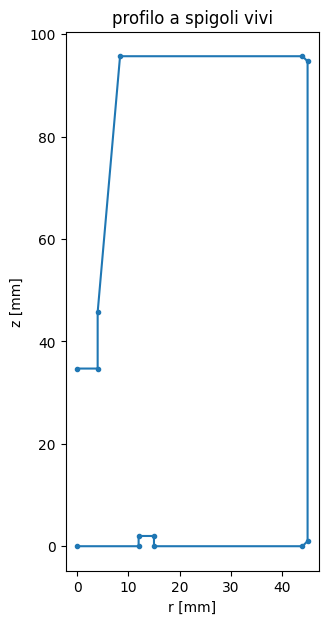

In [4]:
# controllo visivo rapido
pts = build_sharp_profile(geo)
xs, zs = zip(*pts)

fig, ax = plt.subplots(figsize=(4, 7))
ax.plot(xs, zs, "-o", ms=3)
ax.set_aspect("equal")
ax.set_xlabel("r [mm]"); ax.set_ylabel("z [mm]")
ax.set_title("profilo a spigoli vivi")
plt.show()

## 4. Profilo realistico: fondo emisferico + raccordi

Due rifiniture rispetto al profilo grezzo:

1. **Fondo del borehole emisferico** invece che piatto — costruito con un arco esplicito
   (quarto di cerchio di raggio `bh_r`), perché centro e raggio sono noti esattamente.
2. **Raccordi (fillet) sugli spigoli convessi**, ottenuti con il trucco
   `buffer(-f).buffer(+f)`: erodere e poi ri-dilatare arrotonda gli angoli sporgenti.
   (Per arrotondare invece angoli *rientranti* l'ordine andrebbe invertito.)

> ⚠️ **Punto delicato.** Il raccordo va applicato solo a superfici *fisiche*. L'angolo in
> $(0,0)$ sta sull'**asse di simmetria**, che non è una superficie: arrotondarlo mangerebbe
> un millimetro di point contact. Per evitarlo si specchia il profilo **prima** di applicare
> il buffer (così quell'angolo finisce all'interno del materiale e non viene toccato) e si
> ritaglia poi la metà $r \ge 0$.

In [5]:
def build_rounded_profile(geo, fillet=FILLET, n_arc=40):
    """Restituisce (poly_full, poly_half):

      poly_full : sezione intera (r da -R a +R), usata per disegnare il contorno
      poly_half : meta' destra (r >= 0), usata per il calcolo

    Il raccordo viene applicato alla sezione INTERA, cosi' l'angolo in (0,0) - che
    sta sull'asse di simmetria e non e' una superficie fisica - resta intatto.
    Il poligono intero va tenuto cosi' com'e': ricostruirlo dalla meta' lascerebbe
    un segmento residuo lungo r = 0, visibile come una riga grigia nei grafici.
    """
    pts = build_sharp_profile(geo)[:-2]   # via parete cilindrica finale + fondo piatto

    # fondo emisferico del borehole
    z_bore_bottom = geo["H"] - geo["bh_d"]
    z_center = z_bore_bottom + geo["bh_r"]
    pts.append((geo["bh_r"], z_center))
    for th in np.linspace(0, np.pi / 2, n_arc):
        pts.append((geo["bh_r"] * np.cos(th), z_center - geo["bh_r"] * np.sin(th)))
    pts.append((0, z_bore_bottom))

    half_sharp = Polygon(pts)
    assert half_sharp.is_valid, "poligono non valido: controlla l'ordine dei vertici"

    # specchia -> raccorda sull'intero -> ritaglia la meta' destra
    mirrored = shapely.affinity.scale(half_sharp, xfact=-1, origin=(0, 0))
    full_sharp = shapely.union_all([half_sharp, mirrored])
    poly_full = full_sharp.buffer(-fillet, join_style=1).buffer(fillet, join_style=1)

    clip = box(0, -10, geo["R"] + 10, geo["H"] + 10)
    poly_half = poly_full.intersection(clip)

    return poly_full, poly_half


poly_full, poly_half = build_rounded_profile(geo)
print("area mezza sezione:", round(poly_half.area, 2), "mm^2")

# il contorno intero non deve contenere un segmento lungo l'asse
n_axis = np.sum(np.abs(np.array(poly_full.exterior.xy[0])) < 1e-6)
print("punti del contorno a r=0:", n_axis, "(atteso: <= 1)")

area mezza sezione: 3948.88 mm^2
punti del contorno a r=0: 1 (atteso: <= 1)


## 5. Griglia e rasterizzazione

`dr`/`dz` controllano la precisione: più piccoli = più accurato ma più lento (il costo
cresce in fretta). 0.25 mm è un buon compromesso.

> ⚠️ Il `.buffer(1e-6)` è **necessario**: `shapely.contains_xy` è rigorosamente *interno*,
> quindi senza quel gonfiaggio trascurabile tutti i punti esattamente sul bordo — inclusa
> l'intera riga $z=0$, cioè proprio dove sta il point contact! — risulterebbero "fuori",
> e il sistema verrebbe risolto senza alcun elettrodo a potenziale 1 (soluzione tutta zero).

In [6]:
dr = dz = 0.25   # mm

r = np.arange(0, geo["R"] + dr / 2, dr)
z = np.arange(0, geo["H"] + dz / 2, dz)
R, Z = np.meshgrid(r, z)          # shape (nz, nr): asse 0 = z, asse 1 = r

inside = shapely.contains_xy(poly_half.buffer(1e-6), R, Z)

print(f"griglia {R.shape}, nodi dentro il cristallo: {inside.sum()}")

# controllo diagnostico: la riga z=0 DEVE contenere punti (e' dove sta il p+)
row0 = inside[0, :]
assert row0.sum() > 0, "nessun punto dentro a z=0: controlla il buffer!"
print(f"a z=0: {row0.sum()} punti dentro, r da {r[row0].min()} a {r[row0].max()} mm")

griglia (384, 181), nodi dentro il cristallo: 63494
a z=0: 156 punti dentro, r da 0.0 a 43.5 mm


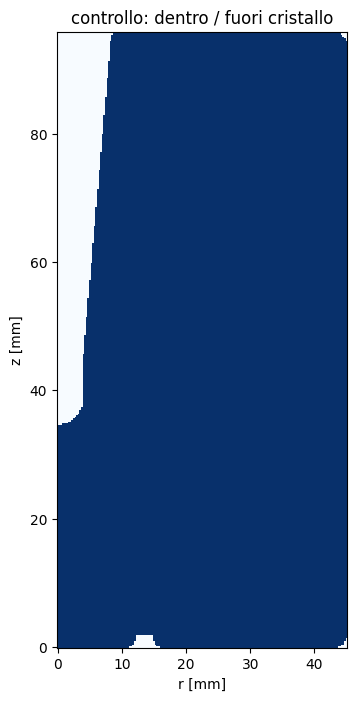

In [7]:
fig, ax = plt.subplots(figsize=(5, 8))
ax.pcolormesh(R, Z, inside, shading="auto", cmap="Blues")
ax.set_aspect("equal")
ax.set_xlabel("r [mm]"); ax.set_ylabel("z [mm]")
ax.set_title("controllo: dentro / fuori cristallo")
plt.show()

## 6. Classificazione dei nodi di bordo

Un nodo è "di bordo" se sta dentro il cristallo ma ha almeno un vicino fuori. Ogni nodo di
bordo viene poi assegnato a un elettrodo in base alla sua posizione:

- `pc` → point contact p+ ($\Phi_w = 1$)
- `np` → contatto n+ ($\Phi_w = 0$)
- `pass` → superficie passivata del groove (Neumann)

In [8]:
def classify_boundary(R, Z, inside, geo):
    up    = np.zeros_like(inside); up[1:, :]     = inside[:-1, :]
    down  = np.zeros_like(inside); down[:-1, :]  = inside[1:, :]
    left  = np.zeros_like(inside); left[:, 1:]   = inside[:, :-1]
    right = np.zeros_like(inside); right[:, :-1] = inside[:, 1:]

    # ATTENZIONE: la colonna i=0 e' l'asse di simmetria, NON una superficie fisica.
    # Senza questa riga i suoi nodi risultano "senza vicino a sinistra", vengono
    # marcati come bordo e finiscono classificati n+ (Phi_w = 0): l'asse verrebbe
    # cortocircuitato a massa e il potenziale sarebbe sbagliato in tutto il volume.
    # Per riflessione, il vicino a sinistra dell'asse e' l'asse stesso.
    left[:, 0] = inside[:, 0]

    is_boundary = inside & ~(up & down & left & right)

    cat = np.full(inside.shape, None, dtype=object)
    for j, i in np.argwhere(is_boundary):
        r_, z_ = R[j, i], Z[j, i]
        if z_ < 1e-6 and r_ <= geo["pc_r"] + 1e-6:
            cat[j, i] = "pc"
        elif z_ <= geo["gr_d"] + 1e-6 and geo["gr_i"] - 1 <= r_ <= geo["gr_o"] + 1:
            cat[j, i] = "pass"
        else:
            cat[j, i] = "np"
    return cat, is_boundary


cat, is_boundary = classify_boundary(R, Z, inside, geo)

n_pc   = int((cat == "pc").sum())
n_np   = int((cat == "np").sum())
n_pass = int((cat == "pass").sum())
print(f"nodi p+ : {n_pc}\nnodi n+ : {n_np}\nnodi passivati : {n_pass}")
assert n_pc > 0 and n_np > 0, "manca un elettrodo: la soluzione sarebbe banale!"

nodi p+ : 45
nodi n+ : 885
nodi passivati : 28


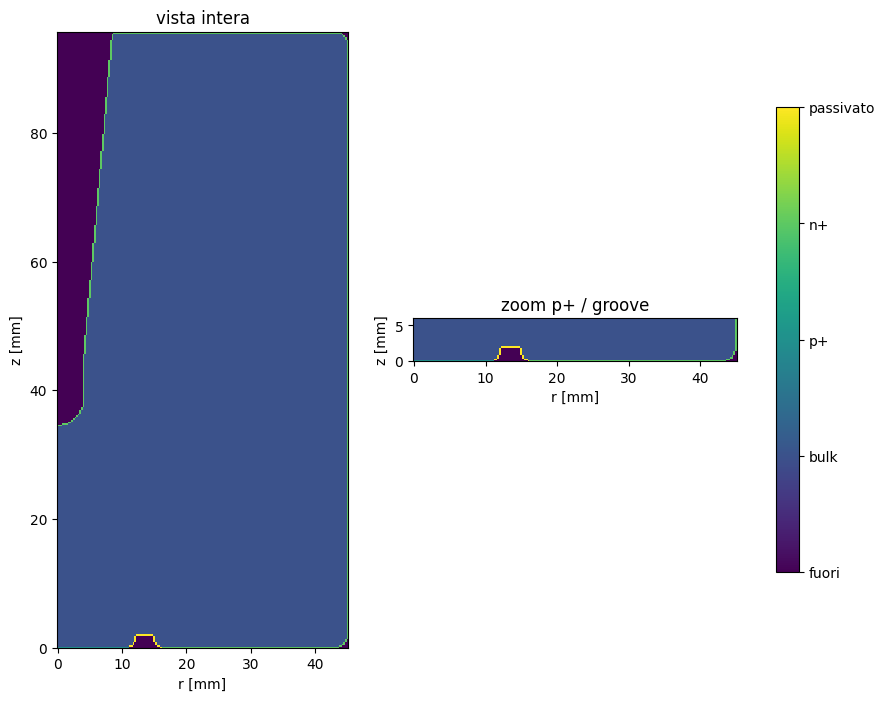

In [9]:
# mappa di controllo della classificazione
img = np.zeros(inside.shape)
img[inside] = 1
img[cat == "pc"] = 2
img[cat == "np"] = 3
img[cat == "pass"] = 4

fig, axs = plt.subplots(1, 2, figsize=(10, 8))
for ax, (zlim, ttl) in zip(axs, [((0, geo["H"]), "vista intera"), ((0, 6), "zoom p+ / groove")]):
    m = ax.pcolormesh(R, Z, img, shading="auto", cmap="viridis", vmin=0, vmax=4)
    ax.set_ylim(*zlim); ax.set_aspect("equal")
    ax.set_xlabel("r [mm]"); ax.set_ylabel("z [mm]"); ax.set_title(ttl)
cb = fig.colorbar(m, ax=axs, fraction=0.03)
cb.set_ticks([0, 1, 2, 3, 4])
cb.set_ticklabels(["fuori", "bulk", "p+", "n+", "passivato"])
plt.show()

## 7. Assemblaggio del sistema lineare

Stencil a 5 punti per il laplaciano assialsimmetrico:

$$\frac{\Phi_E - 2\Phi_0 + \Phi_W}{\Delta r^2} + \frac{\Phi_E - \Phi_W}{2r\,\Delta r}
+ \frac{\Phi_N - 2\Phi_0 + \Phi_S}{\Delta z^2} = 0$$

Due casi speciali:

- **Sull'asse** ($r = 0$) il termine $1/r$ è singolare; il limite (de l'Hôpital) dà
  $4(\Phi_E - \Phi_0)/\Delta r^2$ al posto dei due termini radiali.
- **Neumann**: se un vicino cade fuori dal cristallo, il suo contributo viene semplicemente
  omesso dalla somma — è l'equivalente discreto di "nessun flusso attraverso quella parete".

In [10]:
nz, nr = R.shape

is_dirichlet = np.isin(cat, ["pc", "np"])
is_unknown = inside & ~is_dirichlet

idx_map = -np.ones((nz, nr), dtype=np.int64)
idx_map[is_unknown] = np.arange(is_unknown.sum())
n_unknown = int(is_unknown.sum())

dirichlet_val = np.zeros((nz, nr))
dirichlet_val[cat == "pc"] = 1.0      # n+ resta 0

rows, cols, vals = [], [], []
b = np.zeros(n_unknown)

for j, i in zip(*np.nonzero(is_unknown)):
    row = idx_map[j, i]
    r0 = R[j, i]

    if i == 0:                                   # asse di simmetria
        dirs = [(j + 1, i, 1 / dz**2),
                (j - 1, i, 1 / dz**2),
                (j, i + 1, 4 / dr**2)]
    else:
        aE = 1 / dr**2 + 1 / (2 * r0 * dr)
        aW = 1 / dr**2 - 1 / (2 * r0 * dr)
        dirs = [(j + 1, i, 1 / dz**2),
                (j - 1, i, 1 / dz**2),
                (j, i + 1, aE),
                (j, i - 1, aW)]

    diag = 0.0
    for jj, ii, a in dirs:
        if jj < 0 or jj >= nz or ii < 0 or ii >= nr or not inside[jj, ii]:
            continue                              # Neumann: nessun contributo
        diag -= a
        if is_dirichlet[jj, ii]:
            b[row] -= a * dirichlet_val[jj, ii]   # noto -> passa a destra
        else:
            rows.append(row); cols.append(idx_map[jj, ii]); vals.append(a)
    rows.append(row); cols.append(row); vals.append(diag)

A = sp.csr_matrix((vals, (rows, cols)), shape=(n_unknown, n_unknown))
print(f"incognite: {n_unknown},  nonzeri in A: {A.nnz}")

incognite: 62564,  nonzeri in A: 311682


## 8. Risoluzione

In [11]:
x = spla.spsolve(A, b)

Phi = np.full((nz, nr), np.nan)
Phi[cat == "pc"] = 1.0
Phi[cat == "np"] = 0.0
Phi[is_unknown] = x

print(f"Phi_w: min={np.nanmin(Phi):.4f}  max={np.nanmax(Phi):.4f}")

# sanity check: per il principio del massimo Phi_w deve restare in [0, 1]
assert -1e-9 <= np.nanmin(Phi) and np.nanmax(Phi) <= 1 + 1e-9, "Phi fuori range: qualcosa non va"
assert np.nanmax(Phi) - np.nanmin(Phi) > 0.5, "Phi quasi costante: controlla gli elettrodi"

Phi_w: min=0.0000  max=1.0000


## 9. Campo pesante

$\vec{E}_w = -\nabla \Phi_w$, in unità di 1/mm (Φ è adimensionale).

Prima del gradiente si riempie la regione esterna con il valore valido più vicino
(`distance_transform_edt`): senza questo, i `NaN` si propagherebbero e ai bordi
comparirebbero gradienti fasulli.

In [12]:
ind = distance_transform_edt(~inside, return_distances=False, return_indices=True)
Phi_filled = Phi[tuple(ind)]

dPhi_dz, dPhi_dr = np.gradient(Phi_filled, z, r)
Ew_r = -dPhi_dr
Ew_z = -dPhi_dz
Ew_mag = np.sqrt(Ew_r**2 + Ew_z**2)

print(f"|E_w|: min={np.nanmin(np.where(inside, Ew_mag, np.nan)):.3e}  "
      f"max={np.nanmax(np.where(inside, Ew_mag, np.nan)):.3e}  [1/mm]")

|E_w|: min=0.000e+00  max=3.646e-01  [1/mm]


## 10. Specchiamento per la visualizzazione

Il calcolo gira su $r \ge 0$; per i grafici si riflette la sezione.

> ⚠️ La componente **radiale** del campo cambia segno nella metà specchiata (è un vettore
> che punta verso l'esterno), mentre potenziale e componente $z$ no. Il gradiente va calcolato
> *prima* dello specchiamento, altrimenti sull'asse si crea una discontinuità artificiale.

In [13]:
def mirror(field, flip_sign=False):
    left = field[:, ::-1].copy()
    if flip_sign:
        left = -left
    return np.concatenate([left, field[:, 1:]], axis=1)


r_full = np.concatenate([-r[::-1], r[1:]])

Phi_mir = mirror(np.where(inside, Phi,    np.nan))
E_mir   = mirror(np.where(inside, Ew_mag, np.nan))
Er_mir  = mirror(np.where(inside, Ew_r, 0.0), flip_sign=True)   # <-- cambia segno
Ez_mir  = mirror(np.where(inside, Ew_z, 0.0))
ins_mir = mirror(inside.astype(float)) > 0.5

RF, ZF = np.meshgrid(r_full, z)
print("shape griglia specchiata:", RF.shape, "| Phi_mir:", Phi_mir.shape)

shape griglia specchiata: (384, 361) | Phi_mir: (384, 361)


## 11. Funzione di plot

Ingredienti dello stile:

- **sfondo bianco fuori dal cristallo** — viene gratis dai `NaN`, che matplotlib lascia trasparenti
- **contorno grigio spesso** — disegnato dal bordo del *poligono* (liscio), non dalla griglia (a scalini)
- **equipotenziali** sempre calcolate da $\Phi_w$, anche nel grafico del campo
- **linee di campo** senza frecce: `arrowsize=0`, `broken_streamlines=False` (matplotlib ≥ 3.6)
- `shading="gouraud"` per togliere l'effetto pixelato, `rasterized=True` per PDF leggeri

In [14]:
def plot_section(values, label, norm=None, cmap="magma", vmin=None, vmax=None,
                 draw_streamlines=True, draw_contours=True, figsize=(8, 9)):
    """Plot di una grandezza sulla sezione specchiata, nello stile SolidStateDetectors."""
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.pcolormesh(RF, ZF, values, shading="gouraud", cmap=cmap,
                       norm=norm, vmin=vmin, vmax=vmax, rasterized=True)

    if draw_contours:
        ax.contour(RF, ZF, Phi_mir, levels=np.linspace(0.02, 0.98, 16),
                   colors="white", linewidths=0.45, alpha=0.4)

    if draw_streamlines:
        ax.streamplot(r_full, z,
                      np.where(ins_mir, Er_mir, np.nan),
                      np.where(ins_mir, Ez_mir, np.nan),
                      color="white", linewidth=0.55, density=0.55,
                      arrowsize=0, broken_streamlines=False)

    # contorno del cristallo: poligono intero, cosi' non resta una riga sull'asse
    xs, zs = poly_full.exterior.xy
    ax.plot(xs, zs, color="0.45", lw=2.5, solid_joinstyle="round", zorder=5)

    ax.set_xlabel(r"$r$ in mm", fontsize=13)
    ax.set_ylabel(r"$z$ in mm", fontsize=13)
    ax.set_aspect("equal")
    ax.set_xlim(-geo["R"] - 4, geo["R"] + 4)
    ax.set_ylim(-5, geo["H"] + 6)

    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label(label, fontsize=12)
    fig.tight_layout()
    return fig, ax

## 12. Weighting potential

c:\Users\Utente\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\patches.py:3421: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist
c:\Users\Utente\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\patches.py:3421: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


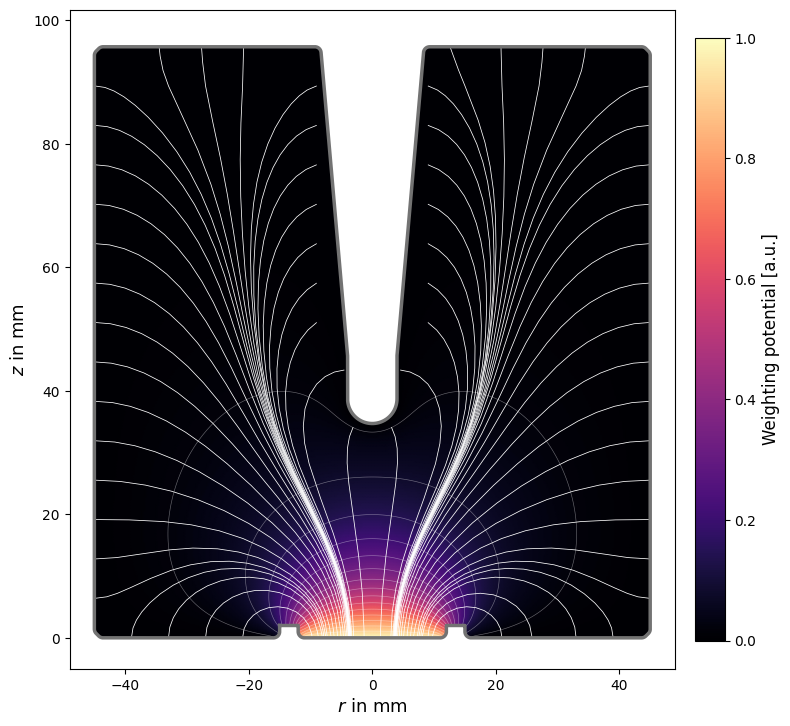

In [15]:
fig, ax = plot_section(Phi_mir, "Weighting potential [a.u.]", vmin=0, vmax=1)
fig.savefig(f"{DET_NAME}_weighting_potential.pdf", dpi=1300, bbox_inches="tight")
plt.show()

## 13. Weighting field

Scala logaritmica: $|E_w|$ varia di ordini di grandezza tra il point contact e il resto del
volume. `vmin`/`vmax` vanno calcolati **solo sui valori finiti e positivi**, altrimenti
`LogNorm` fallisce con `Invalid vmin or vmax`.

scala colore: 1.36e-05 -> 9.57e-02 1/mm


c:\Users\Utente\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\patches.py:3421: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


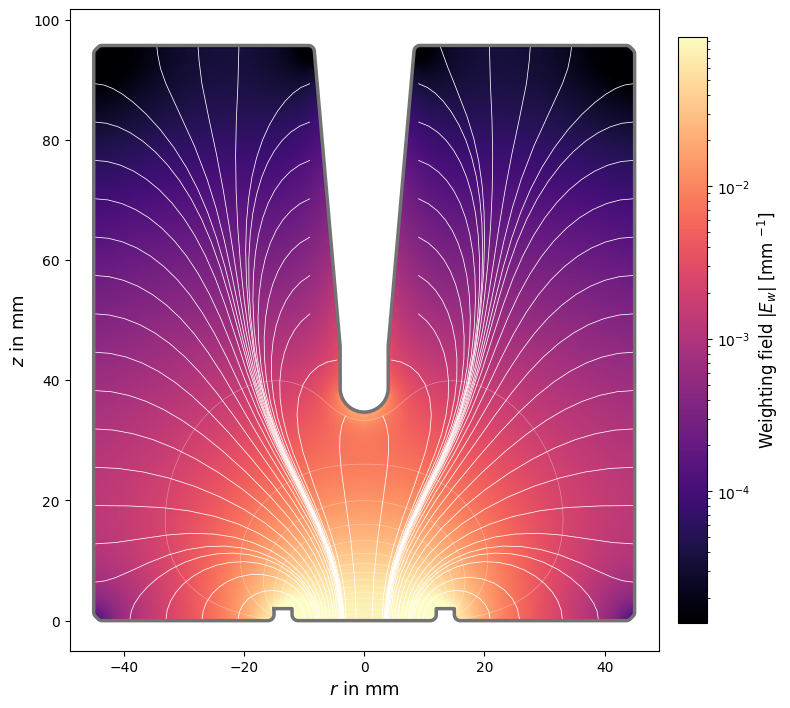

In [16]:
valid = E_mir[np.isfinite(E_mir) & (E_mir > 0)]
vmin, vmax = np.percentile(valid, 1), np.percentile(valid, 99.5)
print(f"scala colore: {vmin:.2e} -> {vmax:.2e} 1/mm")

fig, ax = plot_section(E_mir, r"Weighting field $|E_w|$ [mm $^{-1}]$",
                       norm=LogNorm(vmin=vmin, vmax=vmax))
fig.savefig(f"{DET_NAME}_weighting_field.pdf", dpi=300, bbox_inches="tight")
plt.show()

## 14. Profili 1D

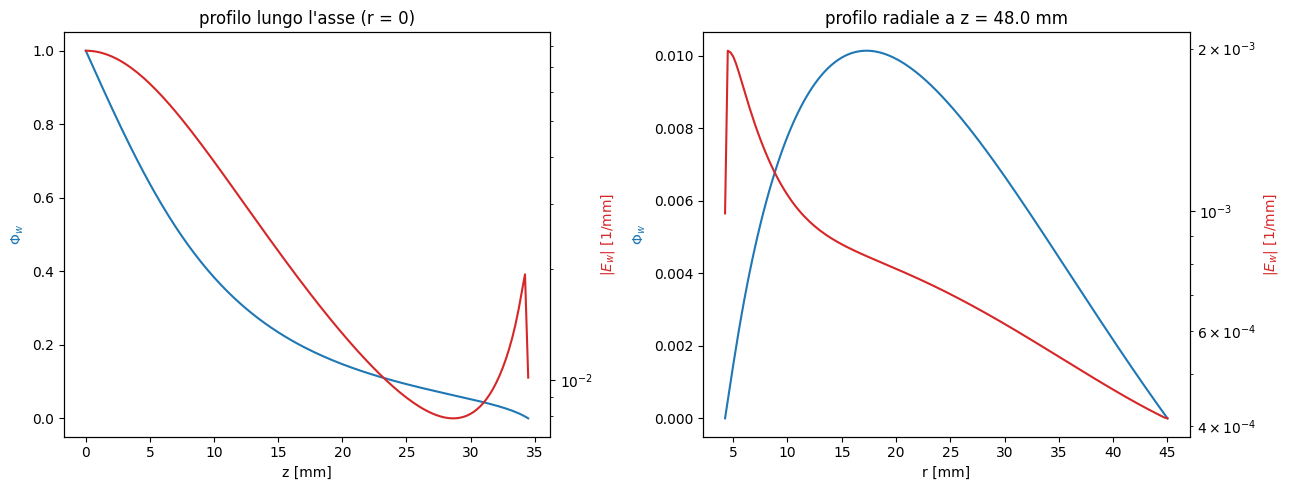

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# lungo l'asse r = 0
m = inside[:, 0]
axs[0].plot(z[m], Phi[m, 0], color="tab:blue")
axs[0].set_xlabel("z [mm]"); axs[0].set_ylabel(r"$\Phi_w$", color="tab:blue")
axs[0].set_title("profilo lungo l'asse (r = 0)")
tw = axs[0].twinx()
tw.plot(z[m], Ew_mag[m, 0], color="tab:red")
tw.set_yscale("log"); tw.set_ylabel(r"$|E_w|$ [1/mm]", color="tab:red")

# radiale a meta' altezza
jmid = len(z) // 2
m2 = inside[jmid, :]
axs[1].plot(r[m2], Phi[jmid, m2], color="tab:blue")
axs[1].set_xlabel("r [mm]"); axs[1].set_ylabel(r"$\Phi_w$", color="tab:blue")
axs[1].set_title(f"profilo radiale a z = {z[jmid]:.1f} mm")
tw2 = axs[1].twinx()
tw2.plot(r[m2], Ew_mag[jmid, m2], color="tab:red")
tw2.set_yscale("log"); tw2.set_ylabel(r"$|E_w|$ [1/mm]", color="tab:red")

plt.tight_layout()
plt.show()

## 15. Salvataggio

I dati vengono salvati in `.npz` per poterli riusare (es. per simulare forme d'impulso con
il teorema di Shockley-Ramo) senza rifare il calcolo.

In [18]:
out = f"{DET_NAME}_weighting.npz"
np.savez_compressed(
    out,
    r=r, z=z, Phi=Phi, Ew_r=Ew_r, Ew_z=Ew_z, Ew_mag=Ew_mag,
    inside=inside, dr=dr, dz=dz, fillet=FILLET, detector=DET_NAME,
)
print("salvato:", out)

salvato: V08682A_weighting.npz


---

## Note e limiti

**Assunzioni geometriche.** Il JSON non specifica univocamente alcuni dettagli, quindi qui si
assume che: la svasatura del borehole allarghi il foro verso l'imbocco superiore; i taper
top/bottom siano smussi sugli spigoli esterni; il fondo del foro sia emisferico; i raccordi
valgano `FILLET = 1.0` mm. Se hai il disegno del produttore, verificali.

**Da controllare nel JSON.** Per questo detector `pp_contact.radius_in_mm = 12`, uguale al
raggio interno del groove: il point contact risulta quindi largo, e la regione ad alto
$\Phi_w$ è una fascia anziché un puntino. Vale la pena verificare se nella convenzione di
`legend-metadata` quel campo indichi davvero il raggio del contatto p+.

**Precisione.** Questo è un solutore a differenze finite su griglia cartesiana: i bordi
obliqui e curvi sono approssimati "a scalini". Va benissimo per analisi esplorative; per
risultati da pubblicare la collaborazione LEGEND usa
[SolidStateDetectors.jl](https://github.com/JuliaPhysics/SolidStateDetectors.jl), che legge
lo stesso formato di metadata e discretizza i contorni molto meglio.

**Campo elettrico vero.** Il campo in V/cm è un'altra cosa: richiede di risolvere **Poisson**
($\nabla^2\Phi = -\rho/\varepsilon$) con la densità di impurezze da `production.impcc` e il
bias reale ai contatti. La struttura del codice è la stessa; cambiano il termine noto `b`
(non più nullo nei nodi interni) e i valori di Dirichlet.
